# Foundations of AI - Lecture 1: Linear Algebra & Statistics

This notebook covers the fundamental concepts from Lecture 1, including:

- Matrix operations
- Statistical measures (mean, median, variance, standard deviation)
- Correlation analysis

**Estimated time: 15 minutes**


## 1. Setting Up: Libraries We'll Use

We'll use the following Python libraries:

- **NumPy**: For numerical computing and matrix operations
- **SciPy**: For advanced statistical functions
- **Matplotlib**: For data visualization


In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Matrix Operations

### 2.1 Matrix Multiplication

Example from the lecture:


In [12]:
# Define matrices from the lecture
A = np.array([[1, 2, 3, 4],
              [2, 0, 9, 7],
              [6, 2, 1, 4]])

B = np.array([[1, 0, 7],
              [2, 2, 9],
              [3, 7, 1],
              [4, 4, 2]])

# Matrix multiplication
C_1 = np.dot(A, B)

# C_2 & C_3 are exactly the same. 
# C_2 is just an operator inhernted from "np.matmul" to make the code more readable
C_2 = A @ B
C_3 = np.matmul(A, B)

print("Matrix A (3x4):")
print(A)
print("\nMatrix B (4x3):")
print(B)
print("\nResult C = A × B (3x3):")
print(C_1)
print()
print(C_2)
print()
print(C_3)
print("\nExpected first row: [30, 41, 36]")


Matrix A (3x4):
[[1 2 3 4]
 [2 0 9 7]
 [6 2 1 4]]

Matrix B (4x3):
[[1 0 7]
 [2 2 9]
 [3 7 1]
 [4 4 2]]

Result C = A × B (3x3):
[[30 41 36]
 [57 91 37]
 [29 27 69]]

[[30 41 36]
 [57 91 37]
 [29 27 69]]

[[30 41 36]
 [57 91 37]
 [29 27 69]]

Expected first row: [30, 41, 36]


### 2.2 Matrix Determinant

The determinant tells us about area and whether a matrix is invertible.


In [13]:
# Matrix with determinant = 2 (from lecture)
A_det = np.array([[2, 0],
                  [0, 1]])

det_A = np.linalg.det(A_det)

print("Matrix A:")
print(A_det)
print(f"\nDeterminant = {det_A}")
print("\nThis represents a horizontal scaling transformation.")

Matrix A:
[[2 0]
 [0 1]]

Determinant = 2.0

This represents a horizontal scaling transformation.


### 2.3 Matrix Inverse

Example from lecture: A = [[2.0, 1.0], [0.5, 1.5]]


In [24]:
# Matrix from the lecture
A = np.array([[2.0, 1.0],
              [0.5, 1.5]])

# Calculate determinant
det_A = np.linalg.det(A)
print("Matrix A:")
print(A)
print(f"\nDeterminant = {det_A}")

# Calculate inverse
A_inv = np.linalg.inv(A)
print("\nInverse A⁻¹:")
print(A_inv)
print("\nExpected: [[0.6, -0.4], [-0.2, 0.8]]")

det_A_inv = np.linalg.det(A_inv)
print(f"\nInverse Matrix Determinant: {det_A_inv}")

# Verify: A × A⁻¹ = I (identity matrix)
I = np.dot(A, A_inv)
print("\nVerification A × A⁻¹ = I:")
print(np.round(I, 10))  # Round to avoid floating point errors
print(I) # Without Round


Matrix A:
[[2.  1. ]
 [0.5 1.5]]

Determinant = 2.5

Inverse A⁻¹:
[[ 0.6 -0.4]
 [-0.2  0.8]]

Expected: [[0.6, -0.4], [-0.2, 0.8]]

Inverse Matrix Determinant: 0.4

Verification A × A⁻¹ = I:
[[ 1.  0.]
 [-0.  1.]]
[[ 1.00000000e+00  0.00000000e+00]
 [-2.77555756e-17  1.00000000e+00]]


## 3. Statistical Measures

### 3.1 Dataset: Height Measurements

Using the height data from the lecture (in cm):


In [25]:
# Height data from the lecture
heights = np.array([165, 178, 182, 159, 174, 188, 171, 163, 179, 176, 184, 169, 167, 173, 181])

print(f"Number of observations: {len(heights)}")
print(f"Heights (cm): {heights}")

Number of observations: 15
Heights (cm): [165 178 182 159 174 188 171 163 179 176 184 169 167 173 181]


### 3.2 Mean

The mean is the average of all values:

$$\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}$$


From Statistics and Probability Perspective. Based on **Monte Carlo Estimation** concept which relises on the **Law of Large Number**, we can say that the mean equals the sample multiplied by the probability of the sample which equals the Expeceted Value of X

$$\mu = \frac{1}{n} \sum_{i=1}^n x_i \approx \sum_{i=1}^n x_i P(x_i) = E[X]$$

$$E[X] \approx \frac{1}{N} \sum_{i=1}^{N} x_i \quad \text{where} \quad x_i \sim P(x)$$

In statistics and probability, the symbol $\sim$ in an equation denotes a sampling or distribution relationship (i.e., "sampled from" or "distributed as"). The mathematical meaning of the expression $x_i \sim P(x)$ is that each sample $x_i$ is drawn randomly according to the probability distribution $P(x)$.

In [39]:
# Calculate mean
mean_height = np.mean(heights)
print(f"Using Mean: {mean_height}")
print(f"Expected from lecture: 173.93 cm")

# Manual calculation to show the formula
manual_mean = np.sum(heights) / len(heights)
print(f"\nManual calculation: {np.sum(heights)} ÷ {len(heights)} = {manual_mean:.2f} cm")

# Using Probability
probability_of_sample = 1 / len(heights)
mean_prob = 0
for sample in heights:
    mean_prob += (sample * probability_of_sample)

print(f"\nUsing Probability: {mean_prob}")

Using Mean: 173.93333333333334
Expected from lecture: 173.93 cm

Manual calculation: 2609 ÷ 15 = 173.93 cm

Using Probability: 173.9333333333333


### 3.3 Median

The median is the middle value in a sorted dataset (50th percentile).


In [41]:
# Calculate median
median_height = np.median(heights)

print("Sorted heights:")
sorted_heights = np.sort(heights)
print(sorted_heights)

print(f"\nMedian (middle value) = {median_height} cm")
print(f"Position: {len(heights)//2 + 1}th value in sorted list")

# For even number of elements, median is average of two middle values
# Example with 14 elements (removing one outlier)
heights_14 = np.array([26, 163, 165, 167, 169, 171, 173, 174, 176, 178, 179, 181, 182, 521])
median_14 = np.median(heights_14)
print(f"\nExample with outliers (n=14): median = {median_14} cm")
print("This is robust to outliers (26 and 521)!")

Sorted heights:
[159 163 165 167 169 171 173 174 176 178 179 181 182 184 188]

Median (middle value) = 174.0 cm
Position: 8th value in sorted list

Example with outliers (n=14): median = 173.5 cm
This is robust to outliers (26 and 521)!


### 3.4 Trimmed Mean

Removes outliers by trimming extreme values:

$$\bar{x}_{trimmed} = \frac{\sum_{i=p+1}^{n-p} x_i}{n - 2p}$$


In [42]:
# Trimmed mean example from lecture
# Remove top 3 and bottom 3 values (p=3)
trimmed_mean = stats.trim_mean(heights, proportiontocut=0.2)  # 20% from each end

print(f"Regular mean: {np.mean(heights):.2f} cm")
print(f"Trimmed mean (20% trim): {trimmed_mean:.2f} cm")

# Manual calculation as shown in lecture
sorted_h = np.sort(heights)
manual_trimmed = np.mean(sorted_h[3:12])  # Remove 3 from each end
print(f"\nManual trimmed mean (lecture example): {manual_trimmed:.2f} cm")
print("Expected from lecture: 174.22 cm")

Regular mean: 173.93 cm
Trimmed mean (20% trim): 174.22 cm

Manual trimmed mean (lecture example): 174.22 cm
Expected from lecture: 174.22 cm


### 3.5 Variance and Standard Deviation

**Variance** measures spread:

$$\sigma^2 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n-1}$$

**Standard deviation** is the square root of variance (same scale as data):

$$\sigma = \sqrt{\frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n-1}}$$


Mean: 173.93
Variance: 68.92
Standard Deviation: 8.30


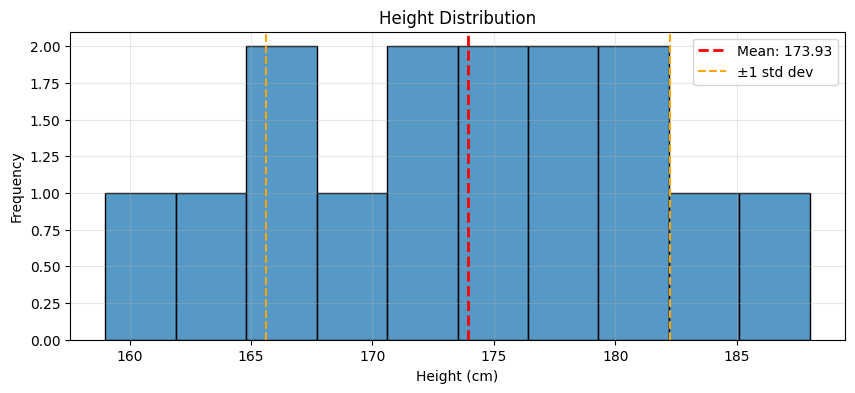

In [60]:
# Calculate variance and standard deviation
variance = np.var(heights, ddof=1) # ddof=1 for sample variance (n-1)
std = np.std(heights, ddof=1) # ddof=1 for sample std dev
mean = np.mean(heights)

print(f"Mean: {mean:.2f}")
print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std:.2f}")

plt.figure(figsize=(10, 4))
sns.histplot(heights, bins=10)
plt.axvline(mean, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean:.2f}")
plt.axvline(mean - std, color='orange', linestyle='--', label=f'±1 std dev')
plt.axvline(mean + std, color='orange', linestyle='--')
plt.xlabel('Height (cm)')
plt.ylabel('Frequency')
plt.title('Height Distribution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 4. Correlation Analysis

### 4.1 Pearson Correlation

Pearson correlation measures **linear** relationships:

$$r = \frac{\text{Cov}(X,Y)}{\sigma_X \sigma_Y} = \frac{\sum_{i=1}^{n}(X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^{n}(X_i - \bar{X})^2} \sqrt{\sum_{i=1}^{n}(Y_i - \bar{Y})^2}}$$

Range: -1 to +1


### 4.1.1 Relation between Cosine similarity and Pearson Correlation

#### The cosine similarity for 2 vectors X and Y
$$\cos(\theta) = \frac{\vec{x} \cdot \vec{y}}{\vert{}\vec{x}\vert{} \vert{}\vec{y}\vert{}}$$

#### If we expand this formula as a summation over each value $i$ in the vector, it would look like this:
$$\cos(\theta) = \frac{\sum_{i=1}^{n} x_i y_i}{\sqrt{\sum_{i=1}^{n} x_i^2} \cdot \sqrt{\sum_{i=1}^{n} y_i^2}}$$

To measure the relationship between two variables, we need to remove the effect of the scale; we do this through "mean centering"—subtracting the mean ($\bar{x}$) from each value so that the mean of the new vector becomes zero.

$$\cos(\theta) = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \cdot \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

$$r = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}$$

Pearson correlation is simply the cosine similarity of mean-centered vectors. And this what makes the range of the correlation within -1 to +1

Pearson correlation coefficient: 0.636

Interpretation:
  r = 1.0  → Perfect positive linear correlation
  r = 0.0  → No linear correlation
  r = -1.0 → Perfect negative linear correlation


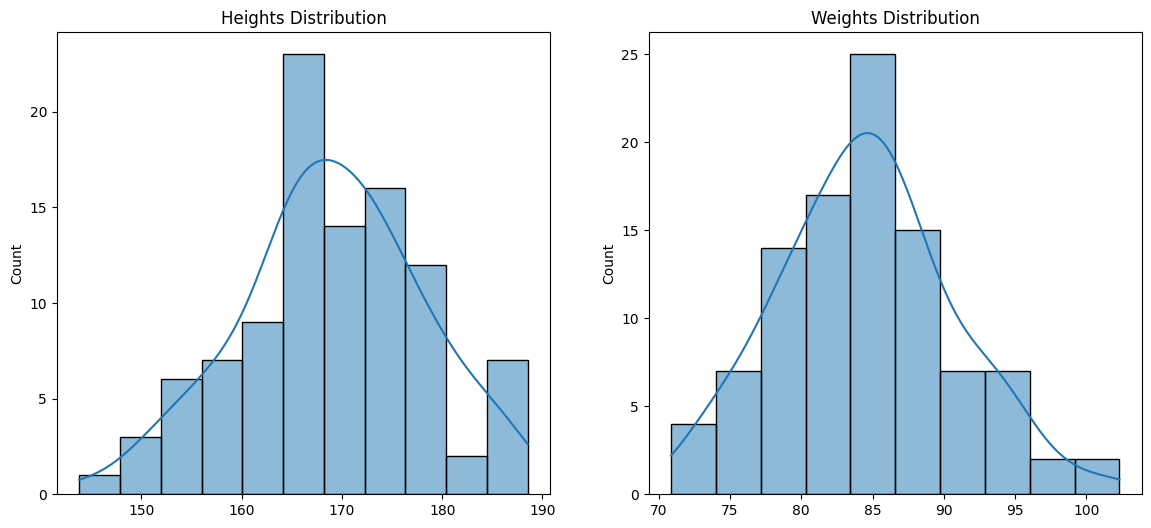

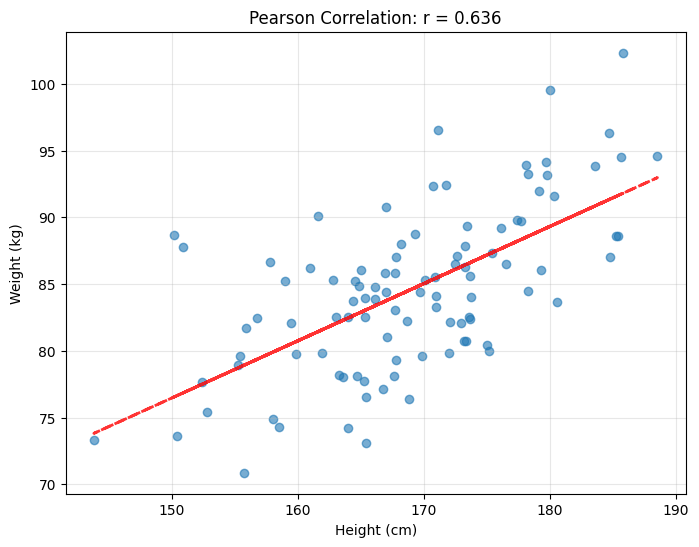

In [83]:
# Generate correlated data (height vs weight)
np.random.seed(42)
heights_data = np.random.normal(170, 10, 100)
weights_data = 0.5 * heights_data + np.random.normal(0, 5, 100)

# Calculate Pearson correlation
pearson_corr, _ = stats.pearsonr(heights_data, weights_data)

print(f"Pearson correlation coefficient: {pearson_corr:.3f}")
print("\nInterpretation:")
print("  r = 1.0  → Perfect positive linear correlation")
print("  r = 0.0  → No linear correlation")
print("  r = -1.0 → Perfect negative linear correlation")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(heights_data, ax=ax[0], kde=True)
ax[0].set_title("Heights Distribution")

sns.histplot(weights_data, ax=ax[1], kde=True)
ax[1].set_title("Weights Distribution")

plt.show()

# Visualize
plt.figure(figsize=(8, 6))
plt.scatter(heights_data, weights_data, alpha=0.6)
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title(f'Pearson Correlation: r = {pearson_corr:.3f}')
plt.grid(True, alpha=0.3)

# Add best fit line
z = np.polyfit(heights_data, weights_data, 1)
p = np.poly1d(z)
plt.plot(heights_data, p(heights_data), "r--", alpha=0.8, linewidth=2)
plt.show()

#### Combining the Probability Distribution of X & Y and the scatters in one visualization **(The Joint Probability Distribution / Multivariate Probability distribution)** For X & Y

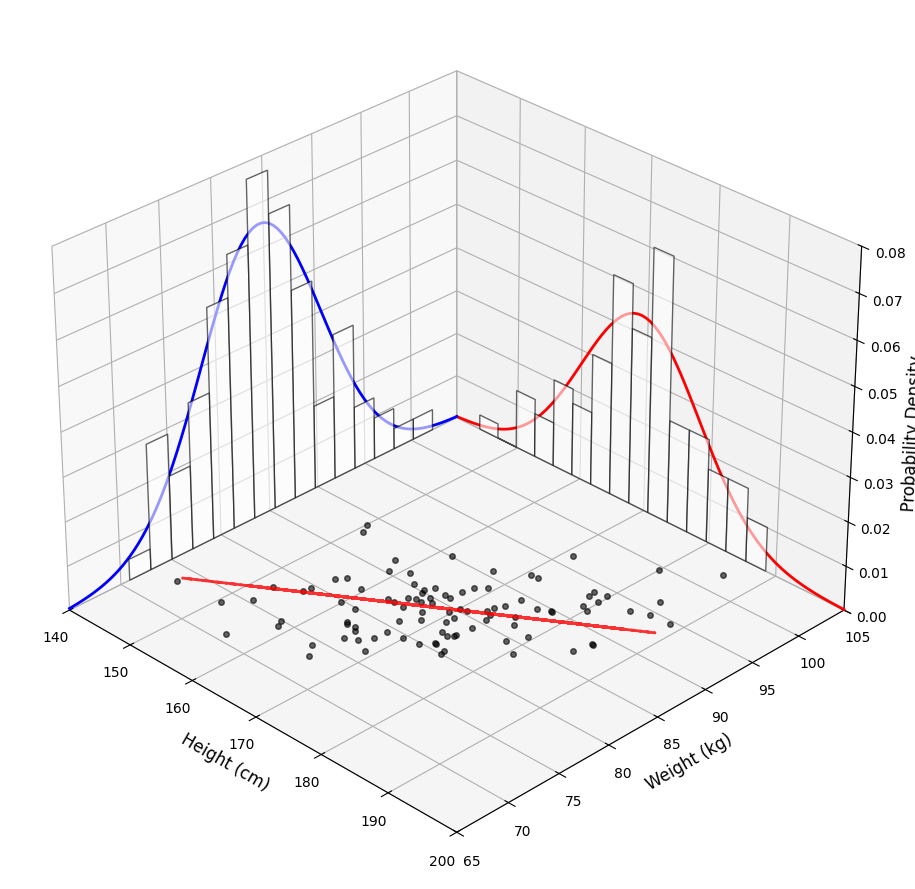

In [ ]:
# Combining the Probability Distribution of X & Y and the scatters in 
#
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# الداتا بتاعتك بالظبط
np.random.seed(42)
heights_data = np.random.normal(170, 10, 100)
weights_data = 0.5 * heights_data + np.random.normal(0, 5, 100)

x = heights_data
y = weights_data

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

x_min, x_max = 140, 200
y_min, y_max = 65, 105
z_max = 0.08 

ax.set_xlim([x_min, x_max])
ax.set_ylim([y_min, y_max])
ax.set_zlim([0, z_max])

# Plot the scatter plot of heights and weights 
ax.plot(x, y, zs=0, zdir='z', marker='o', linestyle='none', color='black', markersize=4, alpha=0.6)

# Best Fit Regression Line
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
ax.plot(x, p(x), "r--", alpha=0.8, linewidth=2)

# Plot the Heights Distribution
hist_x, bins_x = np.histogram(x, bins=15, density=True)
centers_x = (bins_x[:-1] + bins_x[1:]) / 2
width_x = np.diff(bins_x)
ax.bar(centers_x, hist_x, zs=y_max, zdir='y', width=width_x, color='white', edgecolor='black', alpha=0.6)

# PDF line for Heights
x_range = np.linspace(x_min, x_max, 100)
ax.plot(x_range, norm.pdf(x_range, np.mean(x), np.std(x)), zs=y_max, zdir='y', color='red', linewidth=2)

# Plot the Weightss Distribution
hist_y, bins_y = np.histogram(y, bins=15, density=True)
centers_y = (bins_y[:-1] + bins_y[1:]) / 2
width_y = np.diff(bins_y)
ax.bar(centers_y, hist_y, zs=x_min, zdir='x', width=width_y, color='white', edgecolor='black', alpha=0.6)

# PDF line for Weights
y_range = np.linspace(y_min, y_max, 100)
ax.plot(y_range, norm.pdf(y_range, np.mean(y), np.std(y)), zs=x_min, zdir='x', color='blue', linewidth=2)

ax.set_xlabel('Height (cm)', fontsize=12)
ax.set_ylabel('Weight (kg)', fontsize=12)
ax.set_zlabel('Probability Density', fontsize=12)

# Viewing Angle
ax.view_init(elev=30, azim=-45)

plt.tight_layout()
plt.show()

### 4.2 Spearman Correlation

Spearman correlation measures **monotonic** (not necessarily linear) relationships using ranks.

$$\rho = 1 - \frac{6 \sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}$$

$$ -1 \leq \rho \leq +1

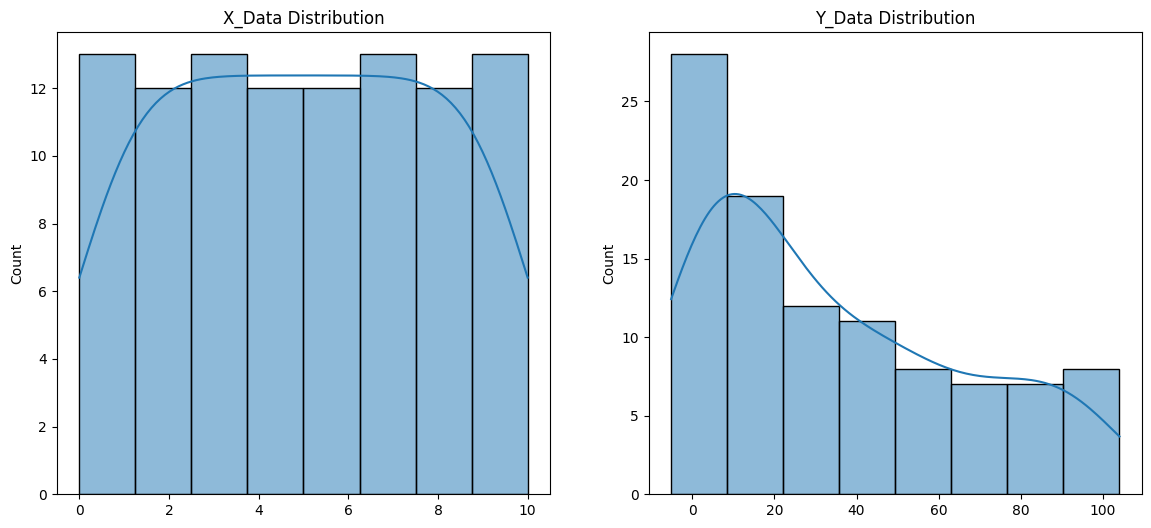

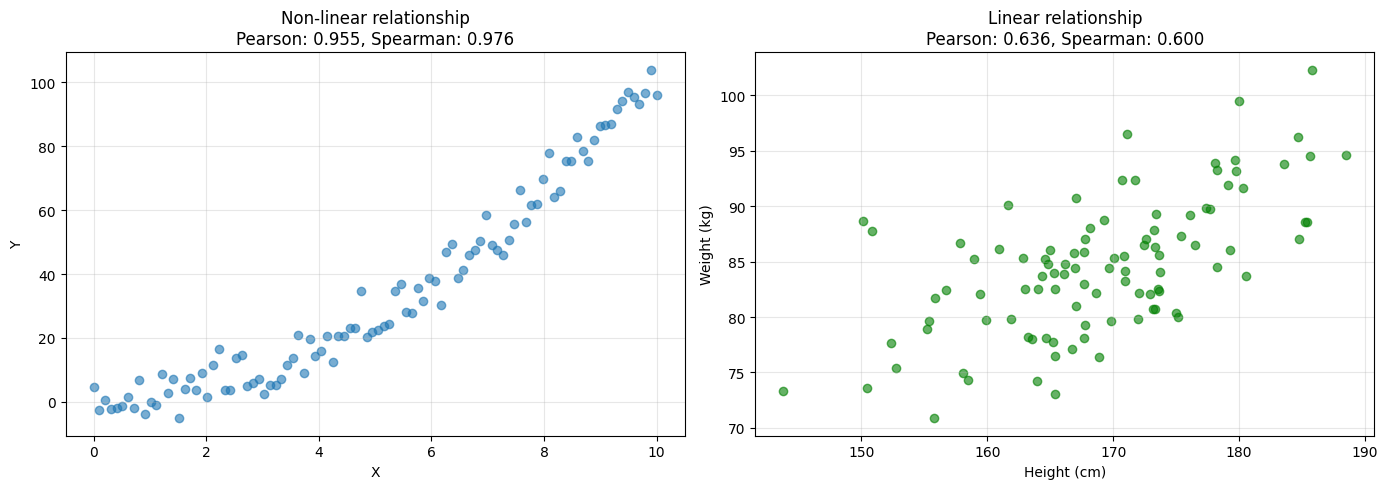

In [94]:
# Generate non-linear but monotonic relationship
x_data = np.linspace(0, 10, 100)
y_data = x_data ** 2 + np.random.normal(0, 5, 100)

# Calculate both correlations 
pearson_corr, _ = stats.pearsonr(x_data, y_data)
spearman_corr, _ = stats.spearmanr(x_data, y_data)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(x_data, ax=ax[0], kde=True)
ax[0].set_title("X_Data Distribution")

sns.histplot(y_data, ax=ax[1], kde=True)
ax[1].set_title("Y_Data Distribution")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Non-linear relationship
axes[0].scatter(x_data, y_data, alpha=0.6)
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].set_title(f'Non-linear relationship\nPearson: {pearson_corr:.3f}, Spearman: {spearman_corr:.3f}')
axes[0].grid(True, alpha=0.3)

# Linear relationship for comparison
p_lin, _ = stats.pearsonr(heights_data, weights_data)
s_lin, _ = stats.spearmanr(heights_data, weights_data)

axes[1].scatter(heights_data, weights_data, alpha=0.6, color='green')
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Weight (kg)')
axes[1].set_title(f'Linear relationship\nPearson: {p_lin:.3f}, Spearman: {s_lin:.3f}')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Covariance Matrix

From the lecture visualization showing perfect correlation (r = 1.00):

$$\Sigma = \begin{bmatrix} \sigma_X^2 & \rho_{X,Y}\sigma_X\sigma_Y \\ \rho_{X,Y}\sigma_X\sigma_Y & \sigma_Y^2 \end{bmatrix}$$

In [95]:
# Create perfectly correlated data
heights_perfect = np.random.normal(170, 10, 100)
weights_perfect = 0.8 * heights_perfect - 50  # Perfect linear relationship

# Calculate covariance matrix
cov_matrix = np.cov(heights_perfect, weights_perfect)

print("Covariance Matrix:")
print(cov_matrix)
print(f"\nVar(Height) = {cov_matrix[0,0]:.2f}")
print(f"Var(Weight) = {cov_matrix[1,1]:.2f}")
print(f"Cov(Height, Weight) = {cov_matrix[0,1]:.2f}")

# Calculate correlation from covariance
correlation = cov_matrix[0, 1] / (np.sqrt(cov_matrix[0, 0]) * np.sqrt(cov_matrix[1, 1]))
print(f"\nCorrelation coefficient: {correlation:.3f}")
print("Expected from lecture: r ≈ 1.00 for perfect correlation")

Covariance Matrix:
[[93.83866053 75.07092842]
 [75.07092842 60.05674274]]

Var(Height) = 93.84
Var(Weight) = 60.06
Cov(Height, Weight) = 75.07

Correlation coefficient: 1.000
Expected from lecture: r ≈ 1.00 for perfect correlation


## 5. Summary

### Key Takeaways:

**Matrix Operations:**

- Matrix multiplication for transformations
- Determinant measures scaling
- Inverse matrix: A × A⁻¹ = I

**Statistical Measures:**

- **Mean**: Average of all values
- **Median**: Middle value (robust to outliers)
- **Trimmed mean**: Removes extreme values
- **Variance**: Measures spread (squared units)
- **Standard deviation**: √variance (same units as data)

**Correlation:**

- **Pearson**: Measures linear relationships (-1 to +1)
- **Spearman**: Measures monotonic relationships (rank-based)
- **Covariance**: Unnormalized measure of joint variability

These concepts are fundamental for understanding AI and machine learning algorithms!
